# W10-D2 · Recurrent Neural Network (RNN) Architectures
## UCAB · Faculty of Engineering
## School of Software Engineering
## **INFO-02020: Artificial Intelligence: Machine Learning**
### **Instructor:** Prof. Didi Ramsaran Chin  

---

### Overview
This notebook demonstrates four primary Recurrent Neural Network (RNN) architectures implemented with vanilla PyTorch `RNNCell`:
1. **One-to-Many:** Single input seed $\to$ sequence of outputs (e.g. image captioning, waveform synthesis).
2. **Many-to-One:** Sequence of inputs $\to$ single summary label (e.g. sentiment analysis, time-series classification, single next-value prediction).
3. **Many-to-Many (Synchronous):** Sequence of inputs $\to$ sequence of outputs aligned at each time step (e.g. POS tagging, next-character prediction, time-series generation).
4. **Encoder-Decoder (Seq2Seq):** Decoupled sequence-to-sequence mapping via an intermediate context vector (e.g. machine translation, sequence inversion).

---
### 0. Environment Setup & Libraries

In [1]:
# avoid kernel crash on macOS
import os
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'

# libraries
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

# reproducibility & device
torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch version: {torch.__version__} | Device: {device}')

PyTorch version: 2.14.1 | Device: cpu


---
### 1. One-to-Many Architecture ($1 \to T$)
- **Data flow:** A single conditioning seed vector $\mathbf{x} \in \mathbb{R}^{d_{seed}}$ unfolds into a temporal sequence $\hat{\mathbf{y}}_1, \dots, \hat{\mathbf{y}}_T$.
- **Toy Task:** A scalar category seed generates a distinct 10-step waveform (Class 0: Ramp, Class 1: Sinusoid, Class 2: Exponential Decay).

One-to-Many Final MSE Loss: 0.000066


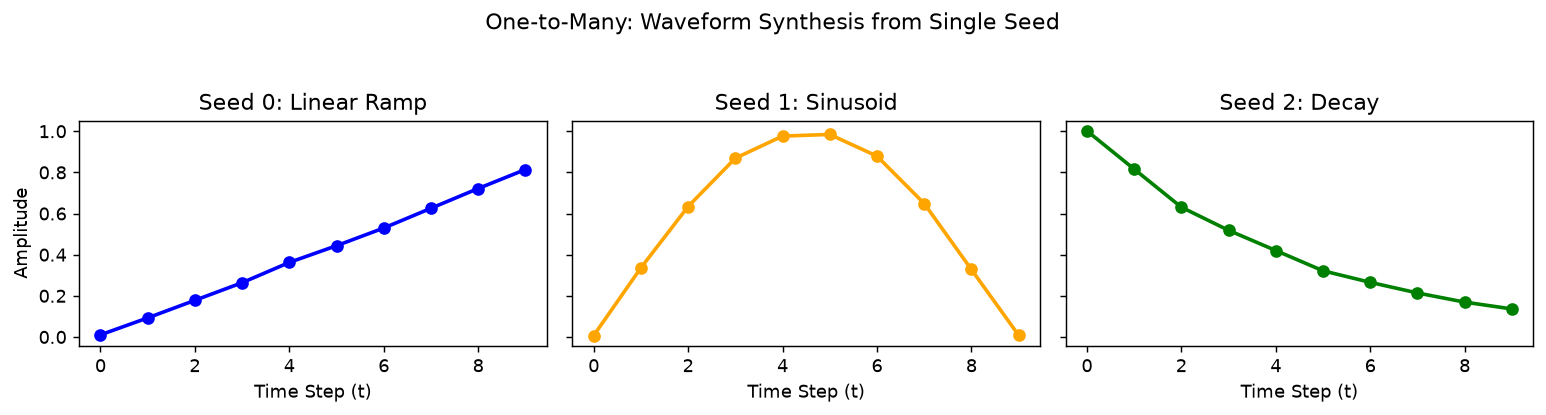

In [2]:
# model: One-to-Many RNN
class OneToManyRNN(nn.Module):
    def __init__(self, d_seed, d_h, d_out, seq_len):
        super().__init__()
        self.seq_len = seq_len
        self.d_out = d_out
        self.seed_to_h0 = nn.Linear(d_seed, d_h)
        self.cell = nn.RNNCell(d_out, d_h)
        self.fc_out = nn.Linear(d_h, d_out)

    def forward(self, seed):
        batch_size = seed.size(0)
        h = torch.tanh(self.seed_to_h0(seed))
        y_prev = torch.zeros(batch_size, self.d_out, device=seed.device)
        
        outputs = []
        for t in range(self.seq_len):
            h = self.cell(y_prev, h)
            y_curr = self.fc_out(h)
            outputs.append(y_curr)
            y_prev = y_curr # autoregressive feedback
        return torch.stack(outputs, dim=1)

# toy data generation (3 seed classes -> 3 distinct waveforms)
N, T = 150, 10
seeds = torch.randint(0, 3, (N,))
seed_1h = torch.zeros(N, 3).scatter_(1, seeds.unsqueeze(1), 1.0)
targets = torch.zeros(N, T, 1)
t_ax = torch.linspace(0, 1, T)

for i in range(N):
    if seeds[i] == 0:
        targets[i, :, 0] = 0.8 * t_ax              # linear ramp
    elif seeds[i] == 1:
        targets[i, :, 0] = torch.sin(np.pi * t_ax)  # sinusoid
    else:
        targets[i, :, 0] = torch.exp(-2.0 * t_ax)   # exponential decay

# train
model_o2m = OneToManyRNN(d_seed=3, d_h=16, d_out=1, seq_len=T)
optimizer = optim.Adam(model_o2m.parameters(), lr=0.03)
criterion = nn.MSELoss()

for epoch in range(100):
    preds = model_o2m(seed_1h)
    loss = criterion(preds, targets)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print(f'One-to-Many Final MSE Loss: {loss.item():.6f}')

# visualize outputs: generated waveforms for each seed class
model_o2m.eval()
test_seeds = torch.eye(3) # seeds 0, 1, 2
with torch.no_grad():
    gen_waves = model_o2m(test_seeds).numpy()

fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
class_labels = ['Seed 0: Linear Ramp', 'Seed 1: Sinusoid', 'Seed 2: Decay']
colors = ['blue', 'orange', 'green']

for k in range(3):
    axes[k].plot(gen_waves[k, :, 0], marker='o', color=colors[k], lw=2)
    axes[k].set_title(class_labels[k])
    axes[k].set_xlabel('Time Step (t)')
axes[0].set_ylabel('Amplitude')
plt.suptitle('One-to-Many: Waveform Synthesis from Single Seed', y=1.05)
plt.tight_layout()
plt.show()

---
### 2. Many-to-One Architecture ($T \to 1$)
- **Data flow:** A sequence of temporal inputs $\mathbf{x}_1, \dots, \mathbf{x}_T$ is condensed into a terminal state $\mathbf{h}_T$ to produce a single categorical or continuous prediction $\hat{\mathbf{y}}$.
- **Toy Task:** Classify a 10-step sequence as either Ascending (Class 0) or Descending (Class 1).

In [3]:
# model: Many-to-One RNN
class ManyToOneRNN(nn.Module):
    def __init__(self, d_in, d_h, num_classes):
        super().__init__()
        self.cell = nn.RNNCell(d_in, d_h)
        self.classifier = nn.Linear(d_h, num_classes)

    def forward(self, x):
        # x: (B, T, d_in)
        batch_size, seq_len, _ = x.size()
        h = torch.zeros(batch_size, self.cell.hidden_size, device=x.device)
        for t in range(seq_len):
            h = self.cell(x[:, t, :], h)
        return self.classifier(h) # terminal state readout

# toy data generation (Ascending vs Descending sequences with noise)
N, T = 120, 10
y_labels = torch.randint(0, 2, (N,))
x_seqs = torch.zeros(N, T, 1)

for i in range(N):
    slope = 0.5 if y_labels[i] == 0 else -0.5
    x_seqs[i, :, 0] = slope * torch.linspace(-1, 1, T) + torch.randn(T) * 0.1

# train
model_m2o = ManyToOneRNN(d_in=1, d_h=12, num_classes=2)
optimizer = optim.Adam(model_m2o.parameters(), lr=0.02)
criterion = nn.CrossEntropyLoss()

for epoch in range(60):
    logits = model_m2o(x_seqs)
    loss = criterion(logits, y_labels)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

acc = (logits.argmax(dim=1) == y_labels).float().mean().item() * 100.0
print(f'Many-to-One Final Loss: {loss.item():.5f} | Classification Accuracy: {acc:.1f}%')

# test on sample sequences and display predictions
sample_x = x_seqs[:4]
sample_y = y_labels[:4]
sample_pred = model_m2o(sample_x).argmax(dim=1)

print('\n=== Many-to-One Sample Predictions ===')
for i in range(4):
    true_cls = "Ascending" if sample_y[i] == 0 else "Descending"
    pred_cls = "Ascending" if sample_pred[i] == 0 else "Descending"
    print(f'Sample {i+1}: True = {true_cls:<10} | Predicted = {pred_cls:<10} | Match = {true_cls == pred_cls}')

Many-to-One Final Loss: 0.00017 | Classification Accuracy: 100.0%

=== Many-to-One Sample Predictions ===
Sample 1: True = Descending | Predicted = Descending | Match = True
Sample 2: True = Descending | Predicted = Descending | Match = True
Sample 3: True = Ascending  | Predicted = Ascending  | Match = True
Sample 4: True = Ascending  | Predicted = Ascending  | Match = True


---
### 3. Many-to-Many Synchronous Architecture ($T \to T$)
- **Data flow:** Input and output sequences share identical lengths ($T_x = T_y = T$). An output $\hat{\mathbf{y}}_t$ is generated at every single temporal step $t$.
- **Toy Task:** Character-level next-token prediction across domain words (`"learn"`, `"model"`, `"train"`).

In [4]:
# model: Many-to-Many Synchronous RNN
class ManyToManySyncRNN(nn.Module):
    def __init__(self, vocab_size, d_h):
        super().__init__()
        self.cell = nn.RNNCell(vocab_size, d_h)
        self.fc_out = nn.Linear(d_h, vocab_size)

    def forward(self, x):
        # x: (B, T, vocab_size)
        batch_size, seq_len, _ = x.size()
        h = torch.zeros(batch_size, self.cell.hidden_size, device=x.device)
        outputs = []
        for t in range(seq_len):
            h = self.cell(x[:, t, :], h)
            outputs.append(self.fc_out(h))
        return torch.stack(outputs, dim=1) # (B, T, vocab_size)

# toy data generation (next-character prediction)
words = ['learn', 'model', 'train']
vocab = sorted(list(set(''.join(words))))
c2i = {c: i for i, c in enumerate(vocab)}
i2c = {i: c for i, c in enumerate(vocab)}
V = len(vocab)
T = 4

x_idx = torch.tensor([[c2i[c] for c in w[:T]] for w in words])
y_idx = torch.tensor([[c2i[c] for c in w[1:T+1]] for w in words])
x_1h = torch.zeros(len(words), T, V).scatter_(2, x_idx.unsqueeze(2), 1.0)

# train
model_m2m = ManyToManySyncRNN(vocab_size=V, d_h=16)
optimizer = optim.Adam(model_m2m.parameters(), lr=0.03)
criterion = nn.CrossEntropyLoss()

for epoch in range(80):
    logits = model_m2m(x_1h)
    loss = criterion(logits.view(-1, V), y_idx.view(-1))
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

token_acc = (logits.argmax(dim=-1) == y_idx).float().mean().item() * 100.0
print(f'Many-to-Many Final Loss: {loss.item():.5f} | Token Accuracy: {token_acc:.1f}%')

# show step-by-step predictions
pred_idx = logits.argmax(dim=-1)
print('\n=== Many-to-Many Step-by-Step Character Predictions ===')
for b, w in enumerate(words):
    in_str   = ' '.join([i2c[i.item()] for i in x_idx[b]])
    tgt_str  = ' '.join([i2c[i.item()] for i in y_idx[b]])
    pred_str = ' '.join([i2c[i.item()] for i in pred_idx[b]])
    print(f"Word '{w}':")
    print(f'  Input:     {in_str}')
    print(f'  Target:    {tgt_str}')
    print(f'  Predicted: {pred_str}')

Many-to-Many Final Loss: 0.00170 | Token Accuracy: 100.0%

=== Many-to-Many Step-by-Step Character Predictions ===
Word 'learn':
  Input:     l e a r
  Target:    e a r n
  Predicted: e a r n
Word 'model':
  Input:     m o d e
  Target:    o d e l
  Predicted: o d e l
Word 'train':
  Input:     t r a i
  Target:    r a i n
  Predicted: r a i n


---
### 4. Encoder-Decoder Architecture ($T_x \to T_y$)
- **Data flow:** Input sequence ($T_x$) is encoded into a bottleneck context vector $\mathbf{c} = \mathbf{h}_{T_x}^{(enc)}$. The decoder initializes with $\mathbf{h}_0^{(dec)} = \mathbf{c}$ and generates the output sequence ($T_y$).
- **Toy Task:** Sequence inversion task ($T_x = 4 \to T_y = 5$ with `<SOS>` and `<EOS>`).

In [5]:
# model: Seq2Seq Encoder-Decoder RNN
class Seq2SeqRNN(nn.Module):
    def __init__(self, vocab_size, d_emb, d_h):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_emb)
        self.enc_cell = nn.RNNCell(d_emb, d_h)
        self.dec_cell = nn.RNNCell(d_emb, d_h)
        self.fc_out = nn.Linear(d_h, vocab_size)

    def forward(self, src, tgt):
        batch_size = src.size(0)
        
        # 1. Encode source sequence -> context vector
        h_enc = torch.zeros(batch_size, self.enc_cell.hidden_size, device=src.device)
        for t in range(src.size(1)):
            emb_t = self.embedding(src[:, t])
            h_enc = self.enc_cell(emb_t, h_enc)
            
        context = h_enc
        
        # 2. Decode target sequence initialized with context
        h_dec = context
        input_tok = tgt[:, 0] # <SOS>
        outputs = []
        for t in range(1, tgt.size(1)):
            dec_emb = self.embedding(input_tok)
            h_dec = self.dec_cell(dec_emb, h_dec)
            logits_t = self.fc_out(h_dec)
            outputs.append(logits_t)
            input_tok = tgt[:, t] # teacher forcing
            
        return torch.stack(outputs, dim=1)

# toy data generation: sequence inversion task
# Vocab: 0:PAD, 1:SOS, 2:EOS, 3..7: symbols
V = 8
SOS_IDX, EOS_IDX = 1, 2
N, T_in = 150, 4

src_data = torch.randint(3, V, (N, T_in))
tgt_data = torch.zeros(N, T_in + 2, dtype=torch.long)
tgt_data[:, 0] = SOS_IDX
for i in range(T_in):
    tgt_data[:, i + 1] = src_data[:, T_in - 1 - i]
tgt_data[:, -1] = EOS_IDX

# train
model_s2s = Seq2SeqRNN(vocab_size=V, d_emb=16, d_h=32)
optimizer = optim.Adam(model_s2s.parameters(), lr=0.03)
criterion = nn.CrossEntropyLoss()

for epoch in range(90):
    logits = model_s2s(src_data, tgt_data)
    loss = criterion(logits.view(-1, V), tgt_data[:, 1:].reshape(-1))
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print(f'Encoder-Decoder Final Loss: {loss.item():.5f}')

# greedy inference on sample sequences
model_s2s.eval()
sample_src = src_data[:4]
sample_tgt = tgt_data[:4, 1:]

with torch.no_grad():
    # encode
    h_enc = torch.zeros(4, 32)
    for t in range(T_in):
        h_enc = model_s2s.enc_cell(model_s2s.embedding(sample_src[:, t]), h_enc)
        
    # decode step-by-step
    h_dec = h_enc
    tok = torch.full((4,), SOS_IDX, dtype=torch.long)
    preds = []
    for t in range(T_in + 1):
        h_dec = model_s2s.dec_cell(model_s2s.embedding(tok), h_dec)
        tok = model_s2s.fc_out(h_dec).argmax(dim=1)
        preds.append(tok)
    preds = torch.stack(preds, dim=1)

print('\n=== Seq2Seq Greedy Inversion Results ===')
for i in range(4):
    in_s   = sample_src[i].tolist()
    true_s = sample_tgt[i].tolist()
    pred_s = preds[i].tolist()
    print(f'Sample {i+1}:')
    print(f'  Input:     {in_s}')
    print(f'  Target:    {true_s}')
    print(f'  Predicted: {pred_s}')
    print(f'  Match:     {true_s == pred_s}')

Encoder-Decoder Final Loss: 0.00196

=== Seq2Seq Greedy Inversion Results ===
Sample 1:
  Input:     [3, 3, 7, 4]
  Target:    [4, 7, 3, 3, 2]
  Predicted: [4, 7, 3, 3, 2]
  Match:     True
Sample 2:
  Input:     [6, 3, 4, 7]
  Target:    [7, 4, 3, 6, 2]
  Predicted: [7, 4, 3, 6, 2]
  Match:     True
Sample 3:
  Input:     [3, 4, 7, 3]
  Target:    [3, 7, 4, 3, 2]
  Predicted: [3, 7, 4, 3, 2]
  Match:     True
Sample 4:
  Input:     [4, 6, 7, 7]
  Target:    [7, 7, 6, 4, 2]
  Predicted: [7, 7, 6, 4, 2]
  Match:     True


---
### Summary: Taxonomy of RNN Architectures

| Architecture | Input Shape $(B, T_x, D_{in})$ | Output Shape $(B, T_y, D_{out})$ | Sequence Alignment | Primary Applications |
|---|---|---|---|---|
| **One-to-Many** | $(B, 1, D_{in})$ | $(B, T_y, D_{out})$ | $T_x = 1 \ll T_y$ | Image Captioning, Music Synthesis |
| **Many-to-One** | $(B, T_x, D_{in})$ | $(B, 1, D_{out})$ | $T_x \gg T_y = 1$ | Sentiment Analysis, Time-Series Classification |
| **Many-to-Many (Sync)** | $(B, T, D_{in})$ | $(B, T, D_{out})$ | $T_x = T_y = T$ | POS Tagging, Next-Token Prediction |
| **Encoder-Decoder** | $(B, T_x, D_{in})$ | $(B, T_y, D_{out})$ | Asynchronous $T_x \neq T_y$ | Machine Translation, Summarization |